In [1]:
from tqdm import tqdm
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn, repeat_interleave
import mlflow
from  mlflow.models import infer_signature

from ml.models import EnsembleComponent, DeepEnsemble, EnsembleComponentConv
from ml.data import QuantumJumpDataset
from ml.train import DeepEnsembleTrainer
from ml.loss import RMSELoss
from ml.types import LossType
from ml.eval import compute_test_error

# Set matplotlib to use TeX for rendering
matplotlib.rcParams.update({"font.size": 16})
plt.rcParams["figure.dpi"] = 125 # set fig resolution

plt.rcParams.update({"text.usetex": True, "font.family": "Helvetica"})

seed = 42  # for reproducibility
torch.manual_seed(seed);

/home/amanuelant/.local/lib/python3.10/site-packages/pymc_marketing/mlflow.py:185: FutureWarning: This functionality is experimental and subject to change. If you encounter any issues or have suggestions, please raise them at: https://github.com/pymc-labs/pymc-marketing/issues/new
  warnings.warn(warning_msg, FutureWarning, stacklevel=1)
/home/amanuelant/.local/lib/python3.10/site-packages/mlflow/pyfunc/utils/data_validation.py:186: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(


In [2]:
fraction = 1.0
full_train_set_size = np.load("data/abc_non_lin_om_data/train/taus.npy").shape[0]
train_set_size = int(full_train_set_size * fraction)

In [3]:
X_train = np.load("data/abc_non_lin_om_data/train/taus.npy")[:train_set_size]
y_train = -np.load("data/abc_non_lin_om_data/train/deltas.npy")[:train_set_size].reshape(-1, 1)

print("X_train.shape:", X_train.shape)
print("y_train.shape:", y_train.shape)
print(f"Max value in training taus: {X_train.max()}")

X_train.shape: (320000, 80)
y_train.shape: (320000, 1)
Max value in training taus: 773.5989990234375


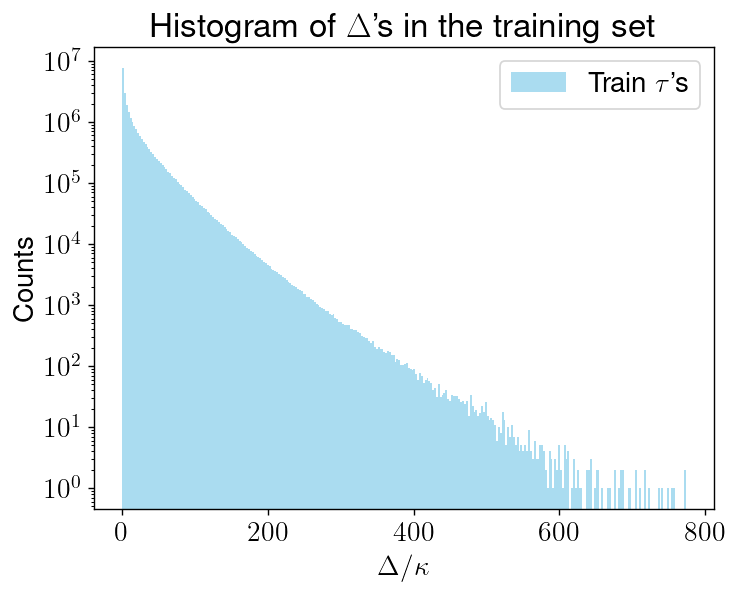

In [4]:
data = [X_train.flatten()]
plt.hist(data[0], bins=300, alpha=0.7, label=fr"Train $\tau$'s", color="skyblue")
plt.xlabel(r"$\Delta/\kappa$")
plt.ylabel("Counts")
plt.yscale("log")
plt.legend()
plt.title(r"Histogram of $\Delta$'s in the training set");

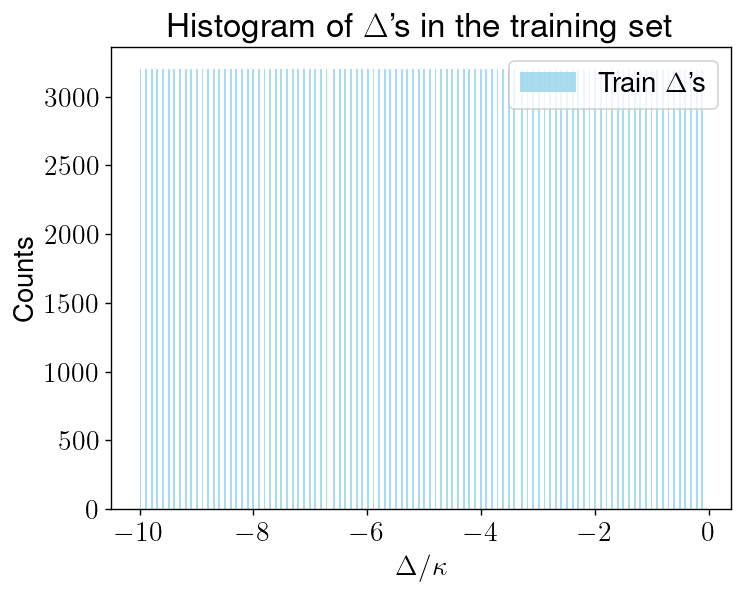

In [5]:
data = [y_train.flatten()]
plt.hist(data[0], bins=300, alpha=0.7, label=fr"Train $\Delta$'s", color="skyblue")
plt.xlabel(r"$\Delta/\kappa$")
plt.ylabel("Counts")
plt.legend()
plt.title(r"Histogram of $\Delta$'s in the training set");

In [6]:
label_noise_std = 0.00

train_dataset = QuantumJumpDataset(
    X_train,
    y_train,
    feature_noise_std=0,
    label_noise_std=label_noise_std,
    seed=seed
)
train_dataset.labels = -train_dataset.labels

# This is not used but need so set it to dummy value
val_dataset = QuantumJumpDataset(
    X_train[:10],
    y_train[:10],
    feature_noise_std=0,
    label_noise_std=label_noise_std,
    seed=seed
)

val_dataset.labels = -val_dataset.labels

In [ ]:
use_conv = True
num_bins = 200
hidden_dims = [128, 64, 32]
num_models = 10

if use_conv:
    models = [
            EnsembleComponentConv(
                out_features=num_bins,
                hidden_dims=hidden_dims,
                output_dim=1, 
                activation=nn.ReLU,
                dropout=0.0
            )
            for _ in range(num_models)
        ]
else:
    models = [
        EnsembleComponent(
            num_bins=num_bins,
            max_val=10,
            min_val=0,
            init_sigma=0.1,
            hidden_dims=hidden_dims,
            output_dim=1, 
            activation=nn.ReLU,
            dropout=0.0
        )
        for _ in range(num_models)
    ]

ensemble = DeepEnsemble(models=models)

In [8]:
print(f"Model architecture:\n\n{models[0]}")

Model architecture:

EnsembleComponentConv(
  (hidden_layers): ModuleList(
    (0): Linear(in_features=200, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): Dropout(p=0.0, inplace=False)
    (7): Linear(in_features=64, out_features=32, bias=True)
    (8): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (9): ReLU()
    (10): Dropout(p=0.0, inplace=False)
  )
  (conv1): Conv1d(1, 100, kernel_size=(6,), stride=(1,), padding=(1,))
  (bn1): BatchNorm1d(100, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv1d(100, 200, kernel_size=(6,), stride=(1,), padding=(1,))
  (bn2): BatchNorm1d(200, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (output_layer): L

In [10]:
lr = 0.001
num_epochs = 50
batch_size = 250
beta1 = 0.87
beta2 = 0.93
adversarial = False
device = 'cuda'

trainer = DeepEnsembleTrainer(
    ensemble_model=ensemble,
    lr=lr,
    weight_decay=0,
    num_epochs=num_epochs,
    batch_size=batch_size,
    beta1=beta1,
    beta2=beta2,
    loss_fn=nn.GaussianNLLLoss,
    val_metric_type=LossType["rmse"],
    device=device,
    use_adversarial=adversarial
)

In [ ]:
mlflow.set_experiment("Deep Ensemble - OM")

Traceback (most recent call last):
  File "/home/amanuelant/.local/lib/python3.10/site-packages/mlflow/store/tracking/file_store.py", line 356, in search_experiments
    exp = self._get_experiment(exp_id, view_type)
  File "/home/amanuelant/.local/lib/python3.10/site-packages/mlflow/store/tracking/file_store.py", line 454, in _get_experiment
    meta = FileStore._read_yaml(experiment_dir, FileStore.META_DATA_FILE_NAME)
  File "/home/amanuelant/.local/lib/python3.10/site-packages/mlflow/store/tracking/file_store.py", line 1595, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
  File "/home/amanuelant/.local/lib/python3.10/site-packages/mlflow/store/tracking/file_store.py", line 1588, in _read_helper
    result = read_yaml(root, file_name)
  File "/home/amanuelant/.local/lib/python3.10/site-packages/mlflow/utils/yaml_utils.py", line 107, in read_yaml
    raise MissingConfigException(f"Yaml file '{file_path}' does not exist.")
mlflow.exceptions.MissingCon

<Experiment: artifact_location='file:///home/amanuelant/ensemble-param-est/mlruns/183553005181605539', creation_time=1772467249956, experiment_id='183553005181605539', last_update_time=1772467249956, lifecycle_stage='active', name='Deep Ensemble - OM', tags={}>

In [ ]:
with mlflow.start_run() as ensemble_run:
    mlflow.log_param("use_conv_layer", use_conv)
    mlflow.log_param("batch_size", batch_size)
    mlflow.log_param("num_epochs", num_epochs)
    mlflow.log_param("beta1", beta1)
    mlflow.log_param("beta2", beta2)
    mlflow.log_param("ensemble_size", num_models)
    mlflow.log_param("adversarial", adversarial)
    mlflow.log_param("label_noise_std", label_noise_std)
    

    trainer.train(
            train_dataset=train_dataset, val_dataset=val_dataset, epochs_per_val=num_epochs-1
        )
    
    mlflow.pytorch.log_model(
        ensemble,
        name="ensemble_model",
        signature=infer_signature(train_dataset[0][0].numpy()),
    )

    run_id = ensemble_run.info.run_id
    model_uri = f"runs:/{run_id}/ensemble_model"

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

print(f"Loading model with uri: {model_uri}")

selected_model = mlflow.pytorch.load_model(model_uri=model_uri)
selected_model = selected_model.to(device)

Loading model with uri: runs:/032ac3aff7df4d7f8ddd79ac31c9e6ed/ensemble_model


In [ ]:
X_test = np.load("data/abc_non_lin_om_data/test/taus.npy")
y_test = -np.load("data/abc_non_lin_om_data/test/deltas.npy")

print(f"Test data (trajectories) shape: {X_test.shape}")
print(f"Test labels shape: {y_test.shape}")
print(f"Max value in test taus: {X_test.max()}")

Test data (trajectories) shape: (80000, 80)
Test labels shape: (80000,)
Max value in test taus: 708.4210205078125


In [ ]:
y_test_depup = np.sort(np.unique(y_test))
X_test_depup = []
for delta in y_test_depup:
    indices = np.where(y_test.flatten() == delta)[0]
    X_test_depup.append(X_test[indices])


X_test_depup = np.array(X_test_depup)
X_test = X_test_depup
y_test = y_test_depup

# X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 80, 1))
print("X_test_depup shape:", X_test_depup.shape)
print("X_test_ shape:", X_test.shape)

X_test_depup shape: (100, 800, 80)
X_test_ shape: (100, 800, 80)


In [ ]:
with torch.no_grad():
    selected_model.eval()
    X_test = torch.from_numpy(X_test).float().to(device)
    y_test = torch.from_numpy(y_test).float().to(device)
    print(f"Test data (trajectories) shape: {X_test.shape}")
    print(f"Test labels shape: {y_test.shape}")
    rmse_loss = RMSELoss()
    rmses, biases = compute_test_error(selected_model, rmse_loss, X_test, y_test)

Test data (trajectories) shape: torch.Size([100, 800, 80])
Test labels shape: torch.Size([100])


In [ ]:
x_abc = np.load("data/om_nonlin/abc/deltas.npy")
y_abc = np.load(f"data/om_nonlin/abc/rmses-label_noise-{label_noise_std}.npy")

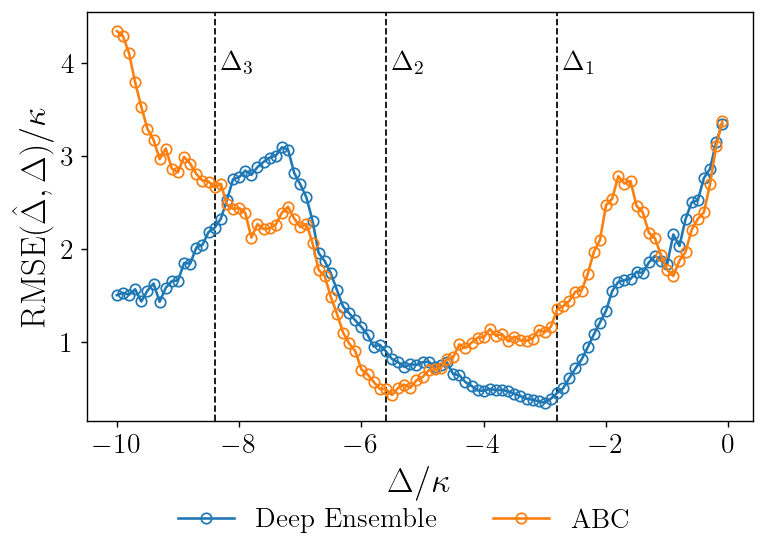

In [ ]:
x_nn = y_test.cpu().numpy()
y_nn = rmses

plt.axvline(x=-2.8, color="black", linestyle='--', linewidth=1)
plt.text(-2.8 + 0.1, 4, r"$\Delta_1$", verticalalignment='center', color='black', rotation='horizontal')
plt.axvline(x=-5.6, color="black", linestyle='--', linewidth=1)
plt.text(-5.6 + 0.1, 4, r"$\Delta_2$", verticalalignment='center', color='black', rotation='horizontal')
plt.axvline(x=-8.4, color="black", linestyle='--', linewidth=1)
plt.text(-8.4 + 0.1, 4, r"$\Delta_3$", verticalalignment='center', color='black', rotation='horizontal')

plt.plot(x_nn, y_nn, marker='o', markerfacecolor="none", label=r'\textrm{Deep Ensemble}')
plt.plot(x_abc, y_abc, marker='o', markerfacecolor="none", label=r'\textrm{ABC}')

plt.xlabel(r"$\Delta/\kappa$", fontsize=20)
plt.ylabel(r"$\textrm{RMSE}(\hat{\Delta}, \Delta)/\kappa$", fontsize=20)

plt.legend(fancybox=True, ncol=2, frameon=False, loc="upper left", bbox_to_anchor=(0.1, -0.15), labelspacing=1.5)
plt.tight_layout()
plt.savefig("figures/abc_ensemble_rmse.png", dpi=300); 